In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

plt.rcParams.update({
  "font.size": 9,
  "axes.titlesize": 9,
  "axes.labelsize": 9,
  "xtick.labelsize": 9,
  "ytick.labelsize": 9,
  "legend.fontsize": 9
})

# tTIS modulates plasticity under minimal somatic firing

In [2]:
cell_id = 19

filename = f"output/temporal-interference-1/{cell_id}/random_poisson/5/noTI_0.1/voltage.csv"
voltage = pd.read_csv(filename, index_col = 0)

filename = f"output/temporal-interference-1/{cell_id}/random_poisson/5/noTI_0.1/synapse_weights.csv"
synapse_weights = pd.read_csv(filename, index_col = 0)

filename = f"output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.5_0.1/voltage.csv"
voltage_50 = pd.read_csv(filename, index_col = 0)

filename = f"output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.5_0.1/synapse_weights.csv"
synapse_weights_50 = pd.read_csv(filename, index_col = 0)

filename = f"output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.9_0.1/voltage.csv"
voltage_90 = pd.read_csv(filename, index_col = 0)

filename = f"output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.9_0.1/synapse_weights.csv"
synapse_weights_90 = pd.read_csv(filename, index_col = 0)

colors = {
  "No tTIS": "black",
  "50% tTIS": "black",
  "90% tTIS": "black"
}

In [3]:
filename = f"output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.5_0.1/synapse_voltage.csv"
synapse = pd.read_csv(filename, index_col = 0)

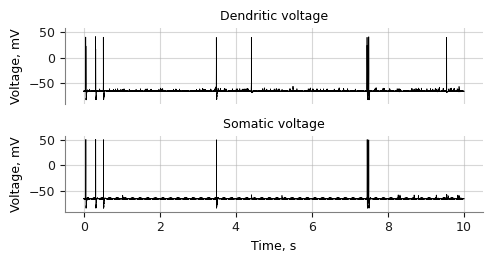

In [4]:
fig, axs = plt.subplots(nrows = 2, ncols = 1, figsize = (5, 2.7), sharey = True)

axs[1].plot(voltage_50.Time / 1000, voltage_50.Voltage, linewidth = 0.5, color = colors["No tTIS"])
# axs[1].plot(voltage_50.Time / 1000, voltage_50.Voltage, linewidth = 0.5, color = colors["50% tTIS"])

axs[0].plot(synapse.Time / 1000, synapse.Synapse7, linewidth = 0.5, color = colors["50% tTIS"])
# axs[2].plot(voltage_90.Time / 1000, voltage_90.Voltage, linewidth = 0.5, color = colors["90% tTIS"])

for ax in axs:
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  ax.spines["bottom"].set_visible(False)
  # ax.spines["left"].set_visible(False)

  ax.grid(alpha = 0.5)

  for spine in ax.spines.values():
    spine.set_color("gray")

  ax.tick_params(axis="both", colors="#1a1a1a")

  ax.set_ylabel("Voltage, mV")

axs[0].tick_params(bottom = None, labelbottom = None)
ax.spines["bottom"].set_visible(True)

axs[1].set_xlabel("Time, s")

axs[1].set_title("Somatic voltage")
axs[0].set_title("Dendritic voltage")

plt.tight_layout()
plt.show()

In [5]:
cell_ids = np.arange(0, 20)

carrier = 1000
beat = 5
frequency = 5
amplitudes_all = [-1, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
amplitudes_selected = [-1, 0.5, 0.9]
synapse_cols = [f"Synapse{idx}" for idx in range(0, 10)]
dendritic_spike_threshold = 20

stimulations = dict()
for amplitude in amplitudes_all:
  if amplitude == -1:
    stim = "noTI"
    stimulations[ stim ] = "No tTIS"
  else:
    stim = f"{carrier}_{beat}_{amplitude}"
    stimulations[ stim ] = f"{amplitude * 100:.0f}%"
  
selected_stimulations = { stim: label for stim, label in stimulations.items() if stim in [f"{carrier}_{beat}_{amp}" for amp in amplitudes_selected] or stim == "noTI" }

In [6]:
def p_to_stars(p):
  if p < 1e-4:
    return "****"
  elif p < 1e-3:
    return "***"
  elif p < 1e-2:
    return "**"
  elif p < 0.05:
    return "*"
  else:
    return "ns"

In [7]:
# Somatic firing frequency
somatic_firing = list()
for cell_id in cell_ids:
  for stim in stimulations.keys():      
    filename = f"output/temporal-interference-1/{cell_id}/random_poisson/{frequency}/{stim}_0.1/spike_frequency.csv"
    n_spikes = len(pd.read_csv(filename, index_col = 0))
    spike_freq = n_spikes / 10

    somatic_firing.append(
      pd.DataFrame({
        "Amplitude": [stimulations[ stim ]],
        "Frequency": [spike_freq]
      })
    )

somatic_firing = pd.concat(somatic_firing)

# Dendritic firing frequency
dendritic_firing = list()
for stim in stimulations.keys():
  print(f"Processing stimulation: {stim}")
  spike_counts = []
  for cell_id in cell_ids:
    filename = f"output/temporal-interference-1/{cell_id}/random_poisson/{frequency}/{stim}_0.1/synapse_voltage.csv"
    synapse_voltage = pd.read_csv(filename, index_col=0)

    syn_v = synapse_voltage[synapse_cols].to_numpy()

    spikes = (syn_v[:-1, :] >= dendritic_spike_threshold) & (syn_v[1:, :] < dendritic_spike_threshold)
    counts = np.sum(spikes, axis=0)

    spike_counts.extend(counts.tolist())

  dendritic_firing.append(
    pd.DataFrame({
      "Amplitude": stimulations[ stim ],
      "Frequency": np.array(spike_counts) / 10
    })
  )

dendritic_firing = pd.concat(dendritic_firing)

Processing stimulation: noTI
Processing stimulation: 1000_5_0.1
Processing stimulation: 1000_5_0.2
Processing stimulation: 1000_5_0.3
Processing stimulation: 1000_5_0.4
Processing stimulation: 1000_5_0.5
Processing stimulation: 1000_5_0.6
Processing stimulation: 1000_5_0.7
Processing stimulation: 1000_5_0.8
Processing stimulation: 1000_5_0.9


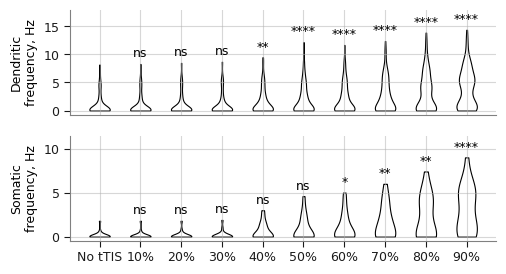

In [8]:
fig, axs = plt.subplots(nrows = 2, ncols = 1, figsize = (5.5, 3), sharex = True)

################## Somatic firing frequency

frequency = dendritic_firing
grouped = list(frequency.groupby("Amplitude"))
labels = [name for name, _ in grouped]
groups = [g["Frequency"].values for _, g in grouped]

# reorder
priority = ["No tTIS"]
order = priority + [l for l in labels if l not in priority]

label_to_group = dict(zip(labels, groups))
labels = order
groups = [label_to_group[l] for l in labels]

# violin plot
vp = axs[0].violinplot(
  groups,
  showmeans=False,
  showmedians=False,
  showextrema=False
)

# style violins
for body in vp["bodies"]:
  body.set_facecolor("white")
  body.set_edgecolor("black")
  body.set_linewidth(0.8)
  body.set_alpha(1)

# ticks
# axs[0].set_xticks(range(1, len(labels) + 1))
# axs[0].set_xticklabels(labels)

axs[0].set_ylabel("Dendritic\nfrequency, Hz")
axs[0].set_xlabel("")

axs[0].xaxis.set_ticks_position("bottom")
axs[0].yaxis.set_ticks_position("left")
axs[0].tick_params(axis="x", bottom=False, top=False, length=4)
axs[0].tick_params(axis="y", left=True, right=False, length=4)

# stats vs No tTIS
ref_idx = labels.index("No tTIS")

y_max = max([g.max() for g in groups])
y_offset = 0.05 * y_max

for i in range(len(groups)):
  if i == ref_idx:
    continue

  stat, p_val = stats.mannwhitneyu(groups[ref_idx], groups[i], alternative="two-sided")
  stars = p_to_stars(p_val)

  x = i + 1
  y = groups[i].max() + y_offset

  axs[0].text(x, y, stars, ha="center", va="bottom")

axs[0].set_ylim(top=y_max + 5 * y_offset)

for spine in ["bottom", "left"]:
  axs[0].spines[spine].set_visible(True)

for spine in ["top", "right"]:
  axs[0].spines[spine].set_visible(False)

axs[0].grid(alpha = 0.5)

####################### Dendritic firing frequency

frequency = somatic_firing
grouped = list(frequency.groupby("Amplitude"))
labels = [name for name, _ in grouped]
groups = [g["Frequency"].values for _, g in grouped]

# reorder
priority = ["No tTIS"]
order = priority + [l for l in labels if l not in priority]

label_to_group = dict(zip(labels, groups))
labels = order
groups = [label_to_group[l] for l in labels]

# violin plot
vp = axs[1].violinplot(
  groups,
  showmeans=False,
  showmedians=False,
  showextrema=False
)

# style violins
for body in vp["bodies"]:
  body.set_facecolor("white")
  body.set_edgecolor("black")
  body.set_linewidth(0.8)
  body.set_alpha(1)

# ticks
axs[1].set_xticks(range(1, len(labels) + 1))
axs[1].set_xticklabels(labels)

axs[1].set_ylabel("Somatic\nfrequency, Hz")
axs[1].set_xlabel("")

axs[1].xaxis.set_ticks_position("bottom")
axs[1].yaxis.set_ticks_position("left")
axs[1].tick_params(axis="x", bottom=True, top=False, length=4)
axs[1].tick_params(axis="y", left=True, right=False, length=4)

# stats vs No TI
ref_idx = labels.index("No tTIS")

y_max = max([g.max() for g in groups])
y_offset = 0.05 * y_max

for i in range(len(groups)):
  if i == ref_idx:
    continue

  stat, p_val = stats.mannwhitneyu(groups[ref_idx], groups[i], alternative="two-sided")
  stars = p_to_stars(p_val)

  x = i + 1
  y = groups[i].max() + y_offset

  axs[1].text(x, y, stars, ha="center", va="bottom")

axs[1].set_ylim(top=y_max + 5.5 * y_offset)

for spine in ["bottom", "left"]:
  axs[1].spines[spine].set_visible(True)

for spine in ["top", "right"]:
  axs[1].spines[spine].set_visible(False)

axs[1].grid(alpha = 0.5)

axs[0].tick_params(bottom = False, labelbottom = False)

for ax in axs:
  for spine in ax.spines.values():
    spine.set_color("gray")

  ax.tick_params(axis="both", colors="#1a1a1a")


In [9]:
filename = f"output/temporal-interference-1/{cell_id}/random_poisson/5/1000_5_0.5_0.1/synapse_weights.csv"
synapse_weights = pd.read_csv(filename, index_col = 0)

filename = f"output/temporal-interference-1/{cell_id}/random_poisson/5/noTI_0.1/synapse_weights.csv"
synapse_weights_no_ti = pd.read_csv(filename, index_col = 0)

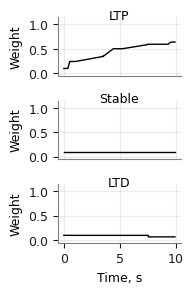

In [10]:
fig, axs = plt.subplots(nrows = 3, ncols = 1, figsize = (2, 3), sharey = True)

for ax, synapse in zip(axs, [ f"Synapse{id}" for id in [8, 6, 9]]):
  ax.plot(synapse_weights.Time / 1000, synapse_weights[synapse], linewidth = 1, color = "black")
  # ax.plot(synapse_weights_no_ti.Time / 1000, synapse_weights_no_ti[synapse], linewidth = 1, color = "black", linestyle = "dotted")
  ax.grid(alpha = 0.25)
  ax.set_ylabel("Weight")
  ax.set_ylim(-0.05, 1.15)

  ax.spines["right"].set_visible(False)
  ax.spines["top"].set_visible(False)

  for spine in ax.spines.values():
    spine.set_color("gray")

  ax.tick_params(axis="both", colors="#1a1a1a")

  ax.set_yticks([0, 0.5, 1])

axs[0].tick_params(bottom = False, labelbottom = False)
axs[1].tick_params(bottom = False, labelbottom = False)

axs[2].set_xlabel("Time, s")

axs[0].set_title("LTP", y = 0.82)
axs[1].set_title("Stable", y = 0.82)
axs[2].set_title("LTD", y = 0.82)

plt.tight_layout()
plt.show()

In [11]:
def categorize(w, atol = 1e-4):
  if w > 0.1 + atol: return "Changed"
  if w < 0.1 - atol: return "Changed"
  return "Stable"

In [12]:
def expand_time(weights, time_step = 0.025, sample_time_step = 0.5, max_time = None):
  # print(f"Original data dimensions: {weights.shape}")
  synapse_cols = [ f"Synapse{id}" for id in range(0, 10) ]
  time = weights.Time
  weights_to_update = weights.copy()[ synapse_cols ]

  if max_time is None:
    max_time = time.max()

  time = (time / time_step).round() * time_step
  weights_to_update.index = time

  new_time = np.arange(0, max_time + time_step, time_step)
  new_weights = pd.DataFrame(weights_to_update).set_index(time).reindex(new_time, method = "ffill")
  # print(f"Expanded data dimensions: {new_weights.shape}")

  if time_step == sample_time_step:
    return new_weights

  # sample every sample_time_step
  sampled_time = np.arange(0, max_time, sample_time_step)
  new_weights = new_weights.loc[sampled_time]
  # print(f"Resampled data dimensions: {new_weights.shape}")

  return new_weights

In [13]:
order = ["LTP", "Stable", "LTD"]
order = ["Changed", "Stable"]

frequency = 5

final_weights = list()
for cell_id in cell_ids:
  for stim in stimulations.keys():
    filename = f"output/temporal-interference-1/{cell_id}/random_poisson/{frequency}/{stim}_0.1/synapse_weights.csv"
    synapse_weights = pd.read_csv(filename, index_col = 0)
    synapse_weights = expand_time(synapse_weights, time_step = 0.025, sample_time_step = 0.025, max_time = 10_000)
    time_select = np.where(synapse_weights.index >= 9.5 * 1000)[0]
    weights = synapse_weights.iloc[ time_select ].mean(axis = 0).tolist()
    
    category = [ categorize(w) for w in weights ]
    final = pd.DataFrame({
      "Amplitude": stimulations[ stim ],
      "Weight": weights,
      "SynapseID": [ f"{synapse}_{cell_id}" for synapse in synapse_cols ],
      "Category": category
    })

    final["Category"] = pd.Categorical(final["Category"], categories = order, ordered = True)

    final_weights.append(final)

final_weights = pd.concat(final_weights, ignore_index = True)
final_weights

,Amplitude,Weight,SynapseID,Category
0,No tTIS,0.199465,Synapse0_0,Changed
1,No tTIS,0.452394,Synapse1_0,Changed
2,No tTIS,0.080258,Synapse2_0,Changed
3,No tTIS,0.761628,Synapse3_0,Changed
4,No tTIS,0.468787,Synapse4_0,Changed
...,...,...,...,...
1995,90%,0.313560,Synapse5_19,Changed
1996,90%,0.337276,Synapse6_19,Changed
1997,90%,0.412360,Synapse7_19,Changed
1998,90%,0.999309,Synapse8_19,Changed


In [14]:
from scipy.stats import chi2_contingency

counts = (
  final_weights
  .groupby(["Amplitude", "Category"], observed = True)
  .size()
  .unstack(fill_value=0)
)

no_ti = counts.loc["No tTIS"].values

final_weight_category_p = {}

for condition in counts.index:
  if condition == "No tTIS":
    continue
  
  other = counts.loc[condition].values
  table = np.vstack([no_ti, other])
  
  chi2, p, dof, expected = chi2_contingency(table)
  final_weight_category_p[condition] = p

final_weight_category_stars = { condition: p_to_stars(p) for condition, p in final_weight_category_p.items() }
final_weight_category_stars

{'10%': 'ns',
 '20%': 'ns',
 '30%': 'ns',
 '40%': 'ns',
 '50%': '**',
 '60%': '**',
 '70%': '****',
 '80%': '****',
 '90%': '****'}

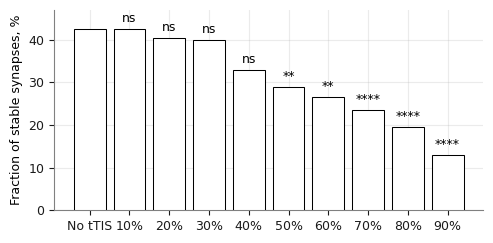

In [15]:
category_counts = (
  final_weights
  .groupby(["Amplitude", "Category"], observed = True)
  .size()
  .reset_index(name = "Count")
)

category_counts = category_counts[ category_counts.Category == "Stable" ]

category_counts["Amplitude"] = pd.Categorical(
    category_counts["Amplitude"],
    categories = ["No tTIS", "10%", "20%", "30%", "40%", "50%", "60%", "70%", "80%", "90%"],
    ordered = True
)

category_counts = category_counts.sort_values("Amplitude")

fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (5, 2.5))
ax = axs

ax.bar(
  category_counts.Amplitude,
  category_counts.Count / 200 * 100,
  color = "white",
  edgecolor = "black",
  zorder = 5,
  linewidth = 0.75
)

ax.grid(alpha = 0.25, zorder = 0)

ax.set_ylabel("Fraction of stable synapses, %")

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

for spine in ax.spines.values():
  spine.set_color("gray")

ax.tick_params(axis="both", colors="#1a1a1a")

for intensity in final_weight_category_stars.keys():
  height = (category_counts[ category_counts.Amplitude == intensity ].Count.values[0] / 200) * 100 + 2.5
  ax.text(
    intensity, height,
    final_weight_category_stars[ intensity ],
    va = "center",
    ha = "center"
  )

ax.set_ylim(0, 47)

plt.tight_layout()
plt.show()

In [51]:
low_intensities = final_weights[
  (final_weights.Amplitude == "No tTIS") |
  (final_weights.Amplitude == "10%") |
  (final_weights.Amplitude == "20%") |
  (final_weights.Amplitude == "30%") |
  (final_weights.Amplitude == "40%") |
  (final_weights.Amplitude == "50%")
]

weight_difference = final_weights.copy()
weight_difference.Weight = abs(weight_difference.Weight - 0.1)

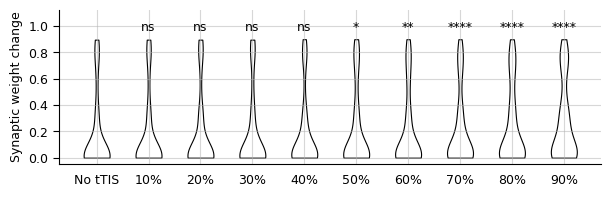

In [53]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (7, 2))
ax = axs

frequency = weight_difference
grouped = list(frequency.groupby("Amplitude"))
labels = [name for name, _ in grouped]
groups = [g["Weight"].values for _, g in grouped]

# reorder
priority = ["No tTIS"]
order = priority + [l for l in labels if l not in priority]

label_to_group = dict(zip(labels, groups))
labels = order
groups = [label_to_group[l] for l in labels]

# violin plot
vp = ax.violinplot(
  groups,
  showmeans=False,
  showmedians=False,
  showextrema=False
)

# style violins
for body in vp["bodies"]:
  body.set_facecolor("white")
  body.set_edgecolor("black")
  body.set_linewidth(0.8)
  body.set_alpha(1)

# ticks
ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels)

ax.set_ylabel("Synaptic weight change")
ax.set_xlabel("")

ax.xaxis.set_ticks_position("bottom")
ax.yaxis.set_ticks_position("left")
ax.tick_params(axis="x", bottom=False, top=False, length=4)
ax.tick_params(axis="y", left=True, right=False, length=4)

# stats vs No tTIS
ref_idx = labels.index("No tTIS")

y_max = max([g.max() for g in groups])
y_offset = 0.05 * y_max

for i in range(len(groups)):
  if i == ref_idx:
    continue

  stat, p_val = stats.ks_2samp(groups[ref_idx], groups[i], alternative="two-sided")
  stars = p_to_stars(p_val)

  x = i + 1
  y = groups[i].max() + y_offset

  ax.text(x, y, stars, ha="center", va="bottom")

ax.set_ylim(top=y_max + 5 * y_offset)

for spine in ["bottom", "left"]:
  ax.spines[spine].set_visible(True)

for spine in ["top", "right"]:
  ax.spines[spine].set_visible(False)

ax.grid(alpha = 0.5)